**Tahap 1 : Penyiapan Data (Data Preparation)**

Menghubungkan Colab ke Google Drive

In [2]:
from google.colab import drive
drive.mount('/content/drive')

MessageError: Error: credential propagation was unsuccessful

Direktori Dataset

In [ ]:
import os

# Path dataset
dataset_path = "/content/drive/MyDrive/Dataset_Bibir_Original"

# Lihat isi direktori utama
print("Isi folder dataset:", os.listdir(dataset_path))

Isi folder dataset: ['train', 'val', 'test']


Rename Nama Gambar

In [ ]:
import os
import shutil

# Path asal dan tujuan
src_root = "/content/drive/MyDrive/Dataset_Bibir_Original"
dst_root = "/content/drive/MyDrive/Dataset_Bibir_Renamed"
image_extensions = ('.jpg', '.jpeg', '.png')

# Copy semua isi folder ke folder baru
for split in ['train', 'val', 'test']:
    src_split_path = os.path.join(src_root, split)
    dst_split_path = os.path.join(dst_root, split)

    if not os.path.exists(dst_split_path):
        os.makedirs(dst_split_path)

    for class_name in os.listdir(src_split_path):
        src_class_path = os.path.join(src_split_path, class_name)
        dst_class_path = os.path.join(dst_split_path, class_name)

        if not os.path.isdir(src_class_path):
            continue

        os.makedirs(dst_class_path, exist_ok=True)

        image_files = [
            f for f in os.listdir(src_class_path)
            if f.lower().endswith(image_extensions)
        ]

        print(f"📁 Menyalin & Rename {len(image_files)} gambar: {split}/{class_name}")

        # Salin dengan rename ke dst
        for i, fname in enumerate(sorted(image_files), start=1):
            ext = os.path.splitext(fname)[1].lower()
            new_name = f"{i}{ext}"
            src_path = os.path.join(src_class_path, fname)
            dst_path = os.path.join(dst_class_path, new_name)
            shutil.copy2(src_path, dst_path)

print("✅ Selesai: Folder baru 'Dataset_Bibir_Renamed' sudah siap dengan file terurut.")

📁 Menyalin & Rename 283 gambar: train/sehat
📁 Menyalin & Rename 315 gambar: train/kurang_sehat
📁 Menyalin & Rename 240 gambar: train/tidak_sehat
📁 Menyalin & Rename 161 gambar: val/sehat
📁 Menyalin & Rename 115 gambar: val/tidak_sehat
📁 Menyalin & Rename 112 gambar: val/kurang_sehat
📁 Menyalin & Rename 112 gambar: test/kurang_sehat
📁 Menyalin & Rename 100 gambar: test/tidak_sehat
📁 Menyalin & Rename 126 gambar: test/sehat
✅ Selesai: Folder baru 'Dataset_Bibir_Renamed' sudah siap dengan file terurut.


In [ ]:
import os

# Path ke dataset yang sudah direname
base_path = '/content/drive/MyDrive/Dataset_Bibir_Renamed'

# Split folder: train, val, test
splits = ['train', 'val', 'test']

for split in splits:
    split_path = os.path.join(base_path, split)
    print(f"\n📁 Jumlah gambar di folder '{split}':")

    if not os.path.isdir(split_path):
        print(f"⛔ Folder '{split}' tidak ditemukan.")
        continue

    # Hitung file di setiap kelas
    for class_name in os.listdir(split_path):
        class_path = os.path.join(split_path, class_name)
        if not os.path.isdir(class_path):
            continue

        total_files = len([
            f for f in os.listdir(class_path)
            if f.lower().endswith(('.jpg', '.jpeg', '.png', '.bmp'))
        ])
        print(f"   🔸 {class_name}: {total_files} file")


📁 Jumlah gambar di folder 'train':
   🔸 sehat: 283 file
   🔸 kurang_sehat: 315 file
   🔸 tidak_sehat: 240 file

📁 Jumlah gambar di folder 'val':
   🔸 sehat: 161 file
   🔸 tidak_sehat: 115 file
   🔸 kurang_sehat: 112 file

📁 Jumlah gambar di folder 'test':
   🔸 kurang_sehat: 112 file
   🔸 tidak_sehat: 100 file
   🔸 sehat: 126 file


In [ ]:
import os

test_path = "/content/drive/MyDrive/Dataset_Bibir_Renamed/test"
print("📂 Isi folder 'test':", os.listdir(test_path))

📂 Isi folder 'test': ['kurang_sehat', 'tidak_sehat', 'sehat']


Menampilkan Contoh Gambar dari 3 Kelas Bibir

In [ ]:
import os
import cv2
import matplotlib.pyplot as plt
import random

# Path dataset
root_path = "/content/drive/MyDrive/Dataset_Bibir_Renamed"

# Daftar split dan label
splits = ['train', 'val', 'test']
class_labels = ['sehat', 'kurang_sehat', 'tidak_sehat']

# Loop untuk setiap split
for split in splits:
    print(f"\n📁 Menampilkan contoh gambar dari folder '{split}':")
    plt.figure(figsize=(12, 4))

    for i, label in enumerate(class_labels):
        label_path = os.path.join(root_path, split, label)
        if not os.path.isdir(label_path):
            print(f"⛔ Folder tidak ditemukan: {label_path}")
            continue

        sample_images = [
            f for f in os.listdir(label_path)
            if f.lower().endswith(('.jpg', '.jpeg', '.png', '.bmp'))
        ]

        if len(sample_images) > 0:
            img_name = random.choice(sample_images)
            img_path = os.path.join(label_path, img_name)

            # Baca dan ubah warna gambar
            img = cv2.imread(img_path)
            img = cv2.cvtColor(img, cv2.COLOR_BGR2RGB)

            # Tampilkan
            plt.subplot(1, 3, i + 1)
            plt.imshow(img)
            plt.title(f"{label.title()}")
            plt.axis('off')
        else:
            print(f"⚠️ Tidak ada gambar di {split}/{label}")

    plt.suptitle(f"Contoh Gambar Tiap Kelas - {split.upper()}", fontsize=14)
    plt.tight_layout()
    plt.show()

Output hidden; open in https://colab.research.google.com to view.

**Tahap 2 : Data Understanding**

In [ ]:
from PIL import Image
import os

# Path dataset utama
root_path = "/content/drive/MyDrive/Dataset_Bibir_Renamed"

# Ekstensi gambar yang didukung
image_extensions = ('.jpg', '.jpeg', '.png', '.bmp', '.gif')

# Split dan label
splits = ['train', 'val', 'test']
class_labels = ['sehat', 'kurang_sehat', 'tidak_sehat']

print("Cek ukuran gambar dari beberapa contoh:\n")

for split in splits:
    print(f"📁 Folder: {split}")
    for label in class_labels:
        label_path = os.path.join(root_path, split, label)
        if not os.path.isdir(label_path):
            print(f"  ⛔ Folder tidak ditemukan: {label_path}")
            continue

        # Ambil semua file gambar
        img_files = [
            f for f in os.listdir(label_path)
            if f.lower().endswith(image_extensions)
        ]

        if img_files:
            sample_img_path = os.path.join(label_path, img_files[0])
            try:
                img = Image.open(sample_img_path)
                print(f"  📌 {label}: {img_files[0]} → {img.size} (width x height)")
            except Exception as e:
                print(f"  ⚠️ Gagal membuka gambar: {sample_img_path} → {e}")
        else:
            print(f"  ⚠️ Tidak ada gambar di folder: {label_path}")
    print()

Cek ukuran gambar dari beberapa contoh:

📁 Folder: train
  📌 sehat: 1.png → (1440, 1440) (width x height)
  📌 kurang_sehat: 1.png → (1440, 1440) (width x height)
  📌 tidak_sehat: 1.png → (1440, 1440) (width x height)

📁 Folder: val
  📌 sehat: 1.png → (1440, 1440) (width x height)
  📌 kurang_sehat: 1.png → (1440, 1440) (width x height)
  📌 tidak_sehat: 1.png → (1440, 1440) (width x height)

📁 Folder: test
  📌 sehat: 1.png → (1088, 1088) (width x height)
  📌 kurang_sehat: 1.png → (1088, 1088) (width x height)
  📌 tidak_sehat: 1.png → (1088, 1088) (width x height)



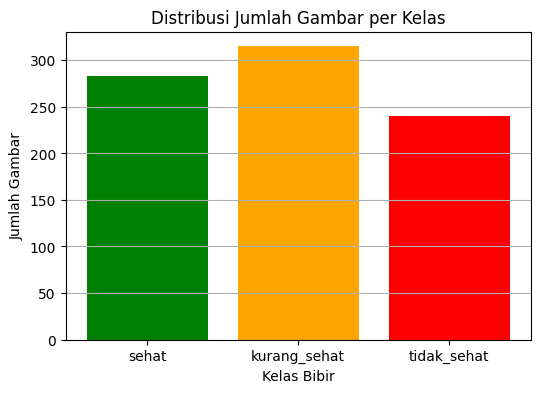

In [ ]:
import matplotlib.pyplot as plt
import os

# Lokasi folder train
dataset_path = "/content/drive/MyDrive/Dataset_Bibir_Renamed/train"

# Label dan ekstensi
class_labels = ['sehat', 'kurang_sehat', 'tidak_sehat']
image_extensions = ('.jpg', '.jpeg', '.png', '.bmp', '.gif')

jumlah_per_kelas = []

# Hitung jumlah file gambar per kelas
for label in class_labels:
    label_path = os.path.join(dataset_path, label)
    if os.path.isdir(label_path):
        img_files = [f for f in os.listdir(label_path) if f.lower().endswith(image_extensions)]
        jumlah_per_kelas.append(len(img_files))
    else:
        jumlah_per_kelas.append(0)
        print(f"⚠️ Folder tidak ditemukan: {label_path}")

# Visualisasi bar chart
plt.figure(figsize=(6, 4))
plt.bar(class_labels, jumlah_per_kelas, color=['green', 'orange', 'red'])
plt.title("Distribusi Jumlah Gambar per Kelas")
plt.ylabel("Jumlah Gambar")
plt.xlabel("Kelas Bibir")
plt.grid(axis='y')
plt.show()

Distribusi Gambar Per Kelas

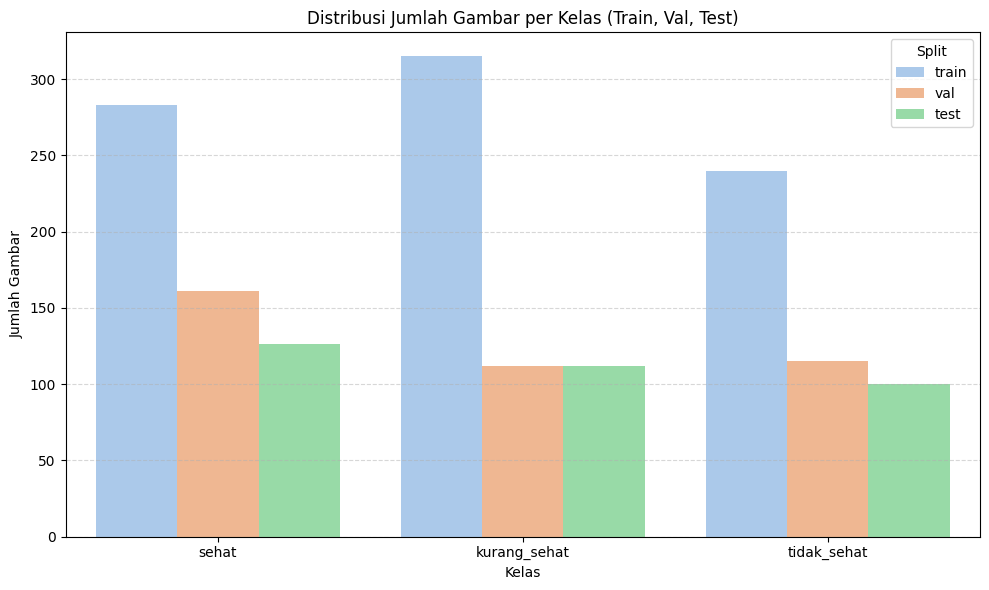

In [ ]:
import os
import seaborn as sns
import matplotlib.pyplot as plt
import pandas as pd

# Path ke dataset crop
base_path = "/content/drive/MyDrive/Dataset_Bibir_Renamed"

# List folder: train, val, test
splits = ['train', 'val', 'test']
data = []

# Loop setiap folder
for split in splits:
    split_path = os.path.join(base_path, split)
    for class_name in os.listdir(split_path):
        class_folder = os.path.join(split_path, class_name)
        if os.path.isdir(class_folder):
            count = len([
                f for f in os.listdir(class_folder)
                if f.lower().endswith(('.png', '.jpg', '.jpeg'))
            ])
            data.append({
                "split": split,
                "class": class_name,
                "count": count
            })

# Buat dataframe
df = pd.DataFrame(data)

# Plot distribusi
plt.figure(figsize=(10,6))
sns.barplot(data=df, x="class", y="count", hue="split", palette="pastel")
plt.title("Distribusi Jumlah Gambar per Kelas (Train, Val, Test)")
plt.ylabel("Jumlah Gambar")
plt.xlabel("Kelas")
plt.grid(axis='y', linestyle='--', alpha=0.5)
plt.legend(title='Split')
plt.tight_layout()
plt.show()

Undersampling Data

In [ ]:
import os
import shutil
import random

# Path folder asal
source_path = "/content/drive/MyDrive/Dataset_Bibir_Renamed"
target_path = "/content/drive/MyDrive/Dataset_Bibir_Balanced"

# Subfolder dan target jumlah per kelas
splits = {
    'train': 230,
    'val': 100,
    'test': 100
}
class_labels = ['sehat', 'kurang_sehat', 'tidak_sehat']
image_exts = ('.jpg', '.jpeg', '.png', '.bmp')

for split, target_count in splits.items():
    print(f"\n📁 Proses split: {split} → {target_count} gambar per kelas")

    for label in class_labels:
        src_dir = os.path.join(source_path, split, label)
        dst_dir = os.path.join(target_path, split, label)

        # Buat folder tujuan
        os.makedirs(dst_dir, exist_ok=True)

        # Ambil semua file gambar valid
        all_images = [
            f for f in os.listdir(src_dir)
            if f.lower().endswith(image_exts) and os.path.isfile(os.path.join(src_dir, f))
        ]

        # Undersample jika jumlah gambar melebihi target
        if len(all_images) >= target_count:
            selected_images = random.sample(all_images, target_count)
        else:
            print(f"⚠️ Jumlah gambar di {split}/{label} kurang dari target ({len(all_images)} < {target_count}), semua akan disalin.")
            selected_images = all_images

        # Salin ke folder baru
        for fname in selected_images:
            shutil.copy2(os.path.join(src_dir, fname), os.path.join(dst_dir, fname))

        print(f"✅ {label} - {len(selected_images)} gambar disalin ke {split}/{label}")

print("\n Selesai: Dataset seimbang disalin ke folder 'Dataset_Bibir_Balanced'")


📁 Proses split: train → 230 gambar per kelas
✅ sehat - 230 gambar disalin ke train/sehat
✅ kurang_sehat - 230 gambar disalin ke train/kurang_sehat
✅ tidak_sehat - 230 gambar disalin ke train/tidak_sehat

📁 Proses split: val → 100 gambar per kelas
✅ sehat - 100 gambar disalin ke val/sehat
✅ kurang_sehat - 100 gambar disalin ke val/kurang_sehat
✅ tidak_sehat - 100 gambar disalin ke val/tidak_sehat

📁 Proses split: test → 100 gambar per kelas
✅ sehat - 100 gambar disalin ke test/sehat
✅ kurang_sehat - 100 gambar disalin ke test/kurang_sehat
✅ tidak_sehat - 100 gambar disalin ke test/tidak_sehat

 Selesai: Dataset seimbang disalin ke folder 'Dataset_Bibir_Balanced'


In [ ]:
import os

# Path dataset seimbang
base_path = '/content/drive/MyDrive/Dataset_Bibir_Balanced'

# Daftar split dan label
splits = ['train', 'val', 'test']
class_labels = ['sehat', 'kurang_sehat', 'tidak_sehat']

print("📊 Jumlah Gambar per Kelas dan Split:\n")

total_gambar = 0

for split in splits:
    split_total = 0
    print(f"📁 Split: {split.upper()}")

    for label in class_labels:
        folder_path = os.path.join(base_path, split, label)

        if not os.path.isdir(folder_path):
            print(f"⛔ Folder tidak ditemukan: {folder_path}")
            continue

        # Hitung hanya file gambar
        file_count = len([
            f for f in os.listdir(folder_path)
            if f.lower().endswith(('.jpg', '.jpeg', '.png', '.bmp'))
        ])
        split_total += file_count
        total_gambar += file_count
        print(f"   📂 {label:<15}: {file_count} gambar")

    print(f"   📌 Total gambar di '{split}': {split_total}\n")

print(f"📦 Total keseluruhan gambar: {total_gambar}")

📊 Jumlah Gambar per Kelas dan Split:

📁 Split: TRAIN
   📂 sehat          : 230 gambar
   📂 kurang_sehat   : 230 gambar
   📂 tidak_sehat    : 230 gambar
   📌 Total gambar di 'train': 690

📁 Split: VAL
   📂 sehat          : 100 gambar
   📂 kurang_sehat   : 100 gambar
   📂 tidak_sehat    : 100 gambar
   📌 Total gambar di 'val': 300

📁 Split: TEST
   📂 sehat          : 100 gambar
   📂 kurang_sehat   : 100 gambar
   📂 tidak_sehat    : 100 gambar
   📌 Total gambar di 'test': 300

📦 Total keseluruhan gambar: 1290


**Tahap 3 : Data Preparation**

In [ ]:
from tensorflow.keras.preprocessing.image import ImageDataGenerator
import matplotlib.pyplot as plt
import os
from PIL import Image
import glob

# Path dataset ke masing-masing folder split
base_path = "/content/drive/MyDrive/Dataset_Bibir_Balanced"
train_dir = os.path.join(base_path, 'train')
val_dir   = os.path.join(base_path, 'val')
test_dir  = os.path.join(base_path, 'test')

# Parameter
image_size = (224, 224)
batch_size = 32

# Fungsi untuk memeriksa apakah berkas adalah gambar yang valid dan menghapus yang tidak valid
def clean_and_validate_images(directory):
    print(f"Memeriksa dan membersihkan folder: {directory}")
    image_extensions = ['*.jpg', '*.jpeg', '*.png', '*.bmp']
    files_to_check = []
    for ext in image_extensions:
        files_to_check.extend(glob.glob(os.path.join(directory, '**', ext), recursive=True))

    invalid_files_count = 0
    for file_path in files_to_check:
        if not is_valid_image(file_path):
            print(f"  Menghapus berkas tidak valid: {file_path}")
            try:
                os.remove(file_path)
                invalid_files_count += 1
            except OSError as e:
                print(f"  Gagal menghapus berkas {file_path}: {e}")
    print(f"Selesai membersihkan: Ditemukan dan dihapus {invalid_files_count} berkas tidak valid.")


# Fungsi untuk memeriksa apakah berkas adalah gambar yang valid (tetap diperlukan untuk fungsi clean)
def is_valid_image(file_path):
    try:
        img = Image.open(file_path)
        img.verify()
        return True
    except (IOError, SyntaxError):
        return False
    except Exception as e:
        # Tangani error lain yang mungkin terjadi saat membuka file
        print(f"Error saat memverifikasi {file_path}: {e}")
        return False


# Bersihkan dan validasi gambar di setiap split
clean_and_validate_images(train_dir)
clean_and_validate_images(val_dir)
clean_and_validate_images(test_dir)


# ImageDataGenerator untuk masing-masing set
train_datagen = ImageDataGenerator(
    rescale=1./255,
    rotation_range=20,
    zoom_range=0.2,
    horizontal_flip=True,
    brightness_range=[0.8, 1.2],
    validation_split=0.0 # Tidak digunakan di sini karena kita memiliki set validasi terpisah
)

val_datagen = ImageDataGenerator(rescale=1./255)
test_datagen = ImageDataGenerator(rescale=1./255)

# Flow dari folder
train_generator = train_datagen.flow_from_directory(
    train_dir,
    target_size=image_size,
    batch_size=batch_size,
    class_mode='categorical',
    color_mode='grayscale',
    shuffle=True,
    classes=['kurang_sehat', 'sehat', 'tidak_sehat'], # Tentukan kelas untuk memastikan urutan
    interpolation='nearest' # Menambahkan metode interpolasi
)

val_generator = val_datagen.flow_from_directory(
    val_dir,
    target_size=image_size,
    batch_size=batch_size,
    class_mode='categorical',
    color_mode='grayscale',
    shuffle=False,
    classes=['kurang_sehat', 'sehat', 'tidak_sehat'], # Tentukan kelas untuk memastikan urutan
    interpolation='nearest' # Menambahkan metode interpolasi
)

test_generator = test_datagen.flow_from_directory(
    test_dir,
    target_size=image_size,
    batch_size=batch_size,
    class_mode='categorical',
    color_mode='grayscale',
    shuffle=False,
    classes=['kurang_sehat', 'sehat', 'tidak_sehat'], # Tentukan kelas untuk memastikan urutan
    interpolation='nearest' # Menambahkan metode interpolasi
)


# Cek mapping label
print("📌 Mapping Label:", train_generator.class_indices)

Memeriksa dan membersihkan folder: /content/drive/MyDrive/Dataset_Bibir_Balanced/train
  Menghapus berkas tidak valid: /content/drive/MyDrive/Dataset_Bibir_Balanced/train/sehat/15.png
Selesai membersihkan: Ditemukan dan dihapus 1 berkas tidak valid.
Memeriksa dan membersihkan folder: /content/drive/MyDrive/Dataset_Bibir_Balanced/val
  Menghapus berkas tidak valid: /content/drive/MyDrive/Dataset_Bibir_Balanced/val/sehat/46.png
  Menghapus berkas tidak valid: /content/drive/MyDrive/Dataset_Bibir_Balanced/val/sehat/24.png
  Menghapus berkas tidak valid: /content/drive/MyDrive/Dataset_Bibir_Balanced/val/sehat/14.png
Selesai membersihkan: Ditemukan dan dihapus 3 berkas tidak valid.
Memeriksa dan membersihkan folder: /content/drive/MyDrive/Dataset_Bibir_Balanced/test
Selesai membersihkan: Ditemukan dan dihapus 0 berkas tidak valid.
Found 689 images belonging to 3 classes.
Found 297 images belonging to 3 classes.
Found 300 images belonging to 3 classes.
📌 Mapping Label: {'kurang_sehat': 0, 's

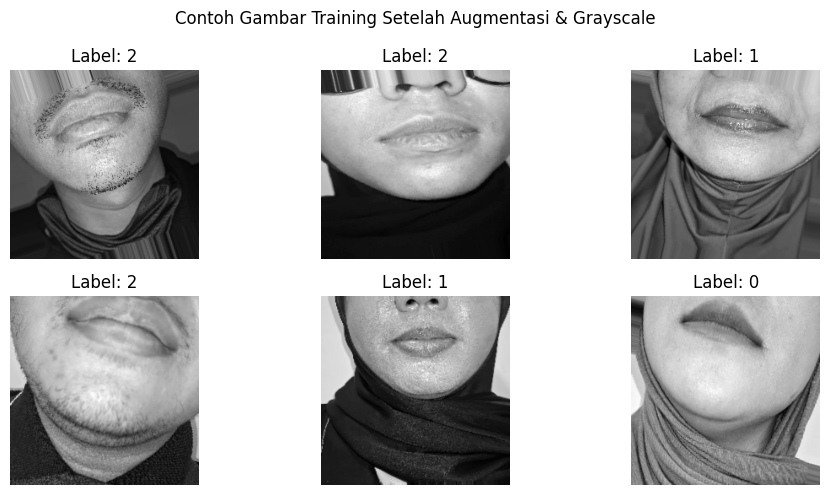

In [ ]:
images, labels = next(train_generator)

plt.figure(figsize=(10, 5))
for i in range(6):
    plt.subplot(2, 3, i + 1)
    # Karena gambar grayscale (H, W, 1), perlu reshape untuk ditampilkan
    plt.imshow(images[i].reshape(image_size), cmap='gray')
    plt.title(f"Label: {labels[i].argmax()}")
    plt.axis('off')

plt.suptitle("Contoh Gambar Training Setelah Augmentasi & Grayscale")
plt.tight_layout()
plt.show()

MODEL CNN

In [ ]:
import tensorflow as tf
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Conv2D, MaxPooling2D, Flatten, Dense, Dropout

model = Sequential([
    # Layer konvolusi pertama
    Conv2D(32, (3, 3), activation='relu', input_shape=(224, 224, 1)),
    MaxPooling2D(pool_size=(2, 2)),

    # Layer konvolusi kedua
    Conv2D(64, (3, 3), activation='relu'),
    MaxPooling2D(pool_size=(2, 2)),

    # Layer konvolusi ketiga
    Conv2D(128, (3, 3), activation='relu'),
    MaxPooling2D(pool_size=(2, 2)),

    # Flatten hasil konvolusi → layer fully connected
    Flatten(),
    Dense(128, activation='relu'),
    Dropout(0.5),  # mencegah overfitting

    # Output layer: 3 kelas → softmax
    Dense(3, activation='softmax')
])

model.summary()

/usr/local/lib/python3.11/dist-packages/keras/src/layers/convolutional/base_conv.py:107: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)


Model: "sequential_4"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ conv2d_12 (Conv2D)              │ (None, 222, 222, 32)   │           320 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_12 (MaxPooling2D) │ (None, 111, 111, 32)   │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_13 (Conv2D)              │ (None, 109, 109, 64)   │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_13 (MaxPooling2D) │ (None, 54, 54, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_14 (Conv2D)              │ (None, 52, 52, 128)    │        73,856 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_14 (MaxPooling2D) │ (None, 26, 26, 128)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten_4 (Flatten)             │ (None, 86528)          │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_8 (Dense)                 │ (None, 128)            │    11,075,712 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_4 (Dropout)             │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_9 (Dense)                 │ (None, 3)              │           387 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 11,168,771 (42.61 MB)

 Trainable params: 11,168,771 (42.61 MB)

 Non-trainable params: 0 (0.00 B)

In [ ]:
# Kompilasi ulang sebelum training
model.compile(
    optimizer='adam',
    loss='categorical_crossentropy',
    metrics=['accuracy']
)

In [ ]:
from tensorflow.keras.callbacks import EarlyStopping

early_stop = EarlyStopping(
    monitor='val_loss',
    patience=5,     # berhenti kalau val_loss tidak membaik dalam 5 epoch
    restore_best_weights=True
)

history = model.fit(
    train_generator,
    epochs=20,
    validation_data=val_generator,
    callbacks=[early_stop]
)

/usr/local/lib/python3.11/dist-packages/keras/src/trainers/data_adapters/py_dataset_adapter.py:121: UserWarning: Your `PyDataset` class should call `super().__init__(**kwargs)` in its constructor. `**kwargs` can include `workers`, `use_multiprocessing`, `max_queue_size`. Do not pass these arguments to `fit()`, as they will be ignored.
  self._warn_if_super_not_called()


Epoch 1/20
22/22 ━━━━━━━━━━━━━━━━━━━━ 156s 7s/step - accuracy: 0.3806 - loss: 1.3075 - val_accuracy: 0.2828 - val_loss: 1.2309
Epoch 2/20
22/22 ━━━━━━━━━━━━━━━━━━━━ 149s 7s/step - accuracy: 0.7072 - loss: 0.7332 - val_accuracy: 0.3704 - val_loss: 1.9792
Epoch 3/20
22/22 ━━━━━━━━━━━━━━━━━━━━ 142s 6s/step - accuracy: 0.7796 - loss: 0.5453 - val_accuracy: 0.2525 - val_loss: 3.4080
Epoch 4/20
22/22 ━━━━━━━━━━━━━━━━━━━━ 150s 7s/step - accuracy: 0.8722 - loss: 0.3310 - val_accuracy: 0.3367 - val_loss: 4.9173
Epoch 5/20
22/22 ━━━━━━━━━━━━━━━━━━━━ 135s 6s/step - accuracy: 0.8630 - loss: 0.3559 - val_accuracy: 0.2290 - val_loss: 8.4779
Epoch 6/20
22/22 ━━━━━━━━━━━━━━━━━━━━ 141s 6s/step - accuracy: 0.8844 - loss: 0.2894 - val_accuracy: 0.2559 - val_loss: 8.1965


evaluation

NameError: name 'history' is not defined

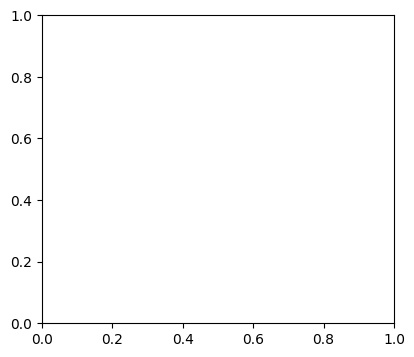

In [1]:
import matplotlib.pyplot as plt

# Plot Accuracy
plt.figure(figsize=(10, 4))
plt.subplot(1, 2, 1)
plt.plot(history.history['accuracy'], label='Train')
plt.plot(history.history['val_accuracy'], label='Validation')
plt.title('Model Accuracy')
plt.xlabel('Epoch')
plt.ylabel('Accuracy')
plt.legend()

# Plot Loss
plt.subplot(1, 2, 2)
plt.plot(history.history['loss'], label='Train')
plt.plot(history.history['val_loss'], label='Validation')
plt.title('Model Loss')
plt.xlabel('Epoch')
plt.ylabel('Loss')
plt.legend()

plt.tight_layout()
plt.show()

evaluasi di test set

In [ ]:
test_loss, test_acc = model.evaluate(test_generator)
print(f"🎯 Akurasi di Test Set: {test_acc:.2f} | Loss: {test_loss:.4f}")

2/2 ━━━━━━━━━━━━━━━━━━━━ 6s 1s/step - accuracy: 0.1900 - loss: 22.0154
🎯 Akurasi di Test Set: 0.16 | Loss: 26.4981


2/2 ━━━━━━━━━━━━━━━━━━━━ 5s 1s/step   


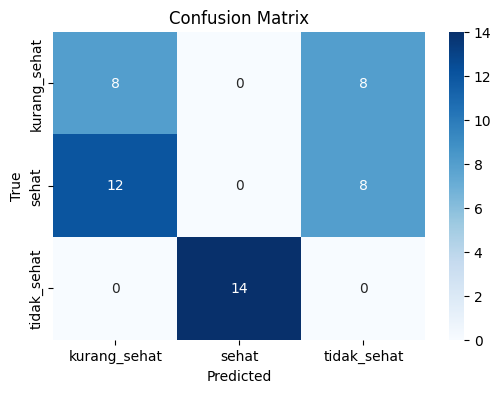

              precision    recall  f1-score   support

kurang_sehat       0.40      0.50      0.44        16
       sehat       0.00      0.00      0.00        20
 tidak_sehat       0.00      0.00      0.00        14

    accuracy                           0.16        50
   macro avg       0.13      0.17      0.15        50
weighted avg       0.13      0.16      0.14        50



In [ ]:
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.metrics import confusion_matrix, classification_report

Prediksi pada test set
Y_pred = model.predict(test_generator)
y_pred = np.argmax(Y_pred, axis=1)
y_true = test_generator.classes

Pastikan urutan label sesuai dengan class_indices
class_labels = list(test_generator.class_indices.keys())

Matriks konfusi
cm = confusion_matrix(y_true, y_pred)

plt.figure(figsize=(6, 4))
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues',
xticklabels=class_labels,
yticklabels=class_labels)
plt.title("Confusion Matrix")
plt.xlabel("Predicted")
plt.ylabel("True")
plt.tight_layout()
plt.show()

Laporan klasifikasi
print("Classification Report:\n")
print(classification_report(y_true, y_pred, target_names=class_labels))

In [ ]:
!pip install mediapipe==0.10.9 numpy==1.26.4 thinc==8.3.6 grpcio-status==1.71.2 ydf==0.13.0 --quiet --upgrade

**SIMPAN MODEL**

In [ ]:
from google.colab import drive
drive.mount('/content/drive')

# Simpan model ke Google Drive
model.save('/content/drive/MyDrive/model_klasifikasi_bibir.h5')
print("✅ Model berhasil disimpan di Google Drive sebagai model_klasifikasi_bibir.h5")


**UJI MODEL DENGAN INPUT DATA BARU**

In [ ]:
from google.colab import drive
drive.mount('/content/drive')

import numpy as np
import tensorflow as tf
import gradio as gr
from tensorflow.keras.preprocessing import image

# Load model CNN klasifikasi bibir (pastikan path-nya sesuai)
model = tf.keras.models.load_model('/content/drive/MyDrive/model_klasifikasi_bibir.h5')

# Label sesuai urutan class_mode / class_indices di generator
class_names = ['kurang_sehat', 'sehat', 'tidak_sehat']  # Pastikan urutannya sesuai dengan training

# Fungsi prediksi gambar bibir
def predict_bibir(img_path):
    # Load dan preprocess gambar
    img = image.load_img(img_path, target_size=(224, 224), color_mode='grayscale')
    img_array = image.img_to_array(img) / 255.0
    img_array = np.expand_dims(img_array, axis=0)  # (1, 224, 224, 1)

    # Prediksi
    pred = model.predict(img_array)[0]
    pred_label = class_names[np.argmax(pred)]
    confidence = np.max(pred)

    result = (
        f"📌 Prediksi Kategori: {pred_label.upper()}\n"
        f"🔢 Probabilitas: {confidence:.4f}\n"
        f"📊 Distribusi Kelas: {dict(zip(class_names, [f'{p:.2%}' for p in pred]))}"
    )
    return result, img_path

# Gradio UI
interface = gr.Interface(
    fn=predict_bibir,
    inputs=gr.Image(type="filepath", label="📷 Upload Gambar Bibir (Warna atau Grayscale)"),
    outputs=[
        gr.Textbox(label="📋 Hasil Prediksi"),
        gr.Image(label="🖼️ Gambar yang Diuji")
    ],
    title="👄 Klasifikasi Bibir Berdasarkan Tekstur",
    description="Upload gambar bibir untuk diklasifikasikan ke dalam kategori: sehat, kurang sehat, atau tidak sehat berdasarkan tekstur visual.",
    allow_flagging="never"
)

interface.launch()